# Flow Q2 – Velocity measurements of open-channel flow

This notebook loads **all measurement files** from the folder `Velocity files for FSI/` and plots them one by one.

**What are the measurements?** (according to `% README.txt`)
- Velocity measurements (2 components: streamwise and vertical) of a steady current over a rough bed in an open channel, Hydraulic Engineering lab, TU Delft.
- Each file = one measurement point in a vertical profile. The file name gives the elevation above the bed as a **percentage of the water depth**: `Z_23.3.dat` → $z = 0.233\,h$.

**Columns in each file (dimensionless):**

| column | quantity | meaning | conversion to dimensional values |
|---|---|---|---|
| 1 | $\tilde t$ | time | $t = \tilde t \cdot h/U$ |
| 2 | $\tilde u$ | streamwise velocity | $u = \tilde u \cdot U$ |
| 3 | $\tilde v$ | vertical (upward) velocity | $v = \tilde v \cdot U$ |

All values are normalised by the mean velocity $U$ and the water depth $h$, so the plots below are **dimensionless**.

### How to read the data and the plots

- **One file = one fixed height.** During each measurement the probe was kept at a fixed elevation $z$ above the bed. Each file is therefore a **time series** at that single height.
- **Together the 14 files form a vertical profile**, from just above the bed ($z = 0.027\,h$) to just below the water surface ($z = 0.944\,h$).
- **x-axis:** dimensionless time $\tilde t = t\,U/h$. Each record lasts roughly $\tilde t \approx 640$–$1000$ with a time step $\Delta\tilde t = 0.0006$, i.e. more than one million samples per file.
- **Top panel:** streamwise velocity $\tilde u = u/U$.
- **Bottom panel:** vertical velocity $\tilde v = v/U$ (positive = upward).
- **Dashed line:** the time average at that height. The fluctuations around it are the turbulent velocity fluctuations, $u' = u - \bar u$ and $v' = v - \bar v$.

### What to expect

- The mean streamwise velocity $\bar{\tilde u}$ **increases with height**, from about 0.43 near the bed to about 1.15 near the surface: the velocity profile of a flow over a rough bed.
- The mean vertical velocity $\bar{\tilde v} \approx 0$ at every height. In a steady, uniform flow there is no net vertical transport, so only the fluctuations remain.
- The standard deviation (turbulence intensity) is **largest close to the bed** and decreases towards the surface.
- To convert to dimensional values, use $U$ and $h$ from the assignment: $t = \tilde t\,h/U$, $u = \tilde u\,U$, $v = \tilde v\,U$.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("Velocity files for FSI")

def load_measurement(filename):
    """Load one measurement file. Columns: t~ (time), u~ (streamwise), v~ (vertical)."""
    path = DATA_DIR / filename
    df = pd.read_csv(path, sep=r"\s+", header=None, names=["t", "u", "v"])
    z_over_h = float(path.stem.split("_")[1]) / 100   # 'Z_23.3' -> 0.233
    return df, z_over_h

def plot_measurement(filename):
    """Plot u~(t~) and v~(t~) of one file, with mean and standard deviation."""
    df, zh = load_measurement(filename)
    dt = df["t"].diff().median()

    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    for ax, col, label, color in [
        (axes[0], "u", r"$\tilde u = u/U$  (streamwise)", "tab:blue"),
        (axes[1], "v", r"$\tilde v = v/U$  (vertical, upward)", "tab:orange"),
    ]:
        mean, std = df[col].mean(), df[col].std()
        ax.plot(df["t"], df[col], lw=0.3, color=color)
        ax.axhline(mean, color="k", ls="--", lw=1, label=f"mean = {mean:.4f}")
        ax.set_ylabel(label)
        ax.legend(loc="upper right")
        ax.text(0.01, 0.95, f"std = {std:.4f}", transform=ax.transAxes, va="top",
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
        ax.grid(alpha=0.3)
    axes[1].set_xlabel(r"$\tilde t = t\,U/h$  (dimensionless time)")
    fig.suptitle(f"File: {filename}   |   measurement height z = {zh:.3f} h above the bed")
    fig.tight_layout()
    plt.show()

    print(f"File               : {DATA_DIR / filename}")
    print(f"Height z/h         : {zh:.3f}")
    print(f"Number of samples  : {len(df)}")
    print(f"Duration t~        : {df['t'].iloc[-1]:.2f}  (time step dt~ = {dt:.4f})")
    print(f"u~ : mean = {df['u'].mean():.4f}, std = {df['u'].std():.4f}, min = {df['u'].min():.4f}, max = {df['u'].max():.4f}")
    print(f"v~ : mean = {df['v'].mean():.4f}, std = {df['v'].std():.4f}, min = {df['v'].min():.4f}, max = {df['v'].max():.4f}")

FILES = sorted(p.name for p in DATA_DIR.glob("Z_*.dat"))
print(f"{len(FILES)} measurement files found:", FILES)

14 measurement files found: ['Z_02.7.dat', 'Z_07.3.dat', 'Z_10.6.dat', 'Z_16.8.dat', 'Z_23.3.dat', 'Z_29.7.dat', 'Z_36.0.dat', 'Z_42.4.dat', 'Z_48.8.dat', 'Z_55.3.dat', 'Z_61.5.dat', 'Z_74.4.dat', 'Z_87.0.dat', 'Z_94.4.dat']


## 1. `Z_02.7.dat` — measurement at $z = 0.027\,h$

Source: `Velocity files for FSI/Z_02.7.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

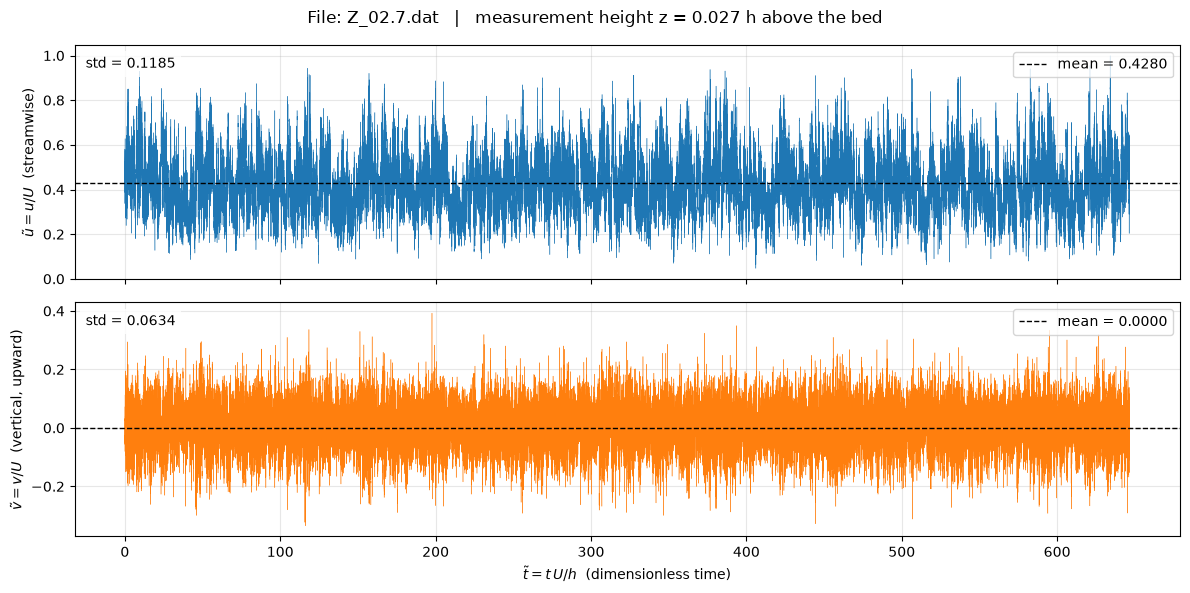

File               : Velocity files for FSI\Z_02.7.dat
Height z/h         : 0.027
Number of samples  : 1081344
Duration t~        : 646.74  (time step dt~ = 0.0006)
u~ : mean = 0.4280, std = 0.1185, min = 0.0470, max = 0.9995
v~ : mean = 0.0000, std = 0.0634, min = -0.3351, max = 0.3925


In [2]:
plot_measurement("Z_02.7.dat")

## 2. `Z_07.3.dat` — measurement at $z = 0.073\,h$

Source: `Velocity files for FSI/Z_07.3.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

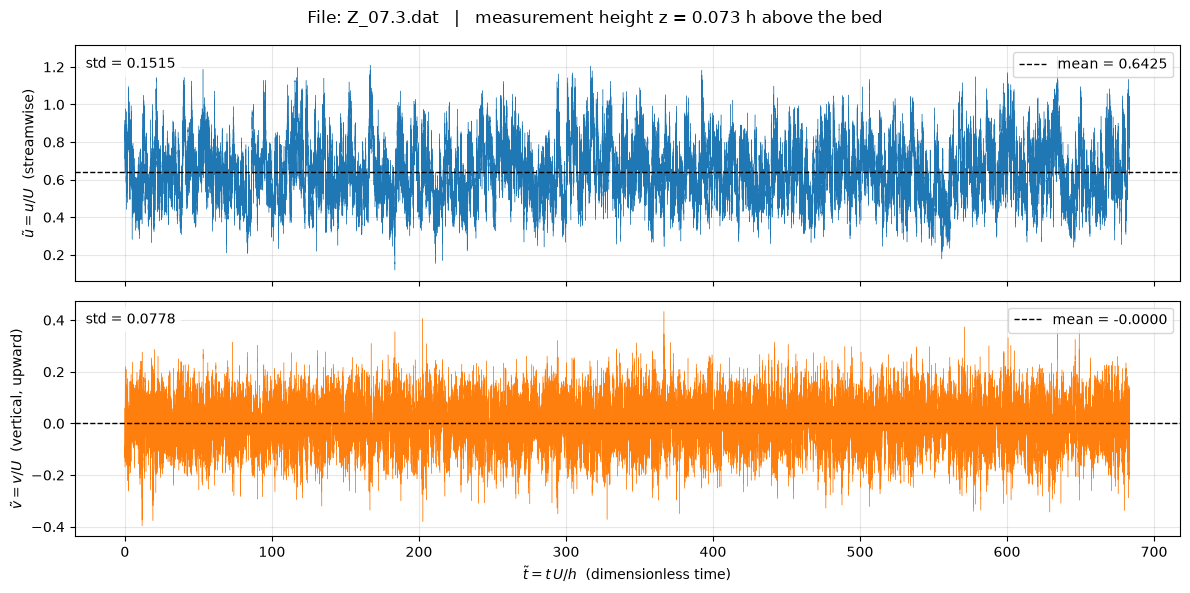

File               : Velocity files for FSI\Z_07.3.dat
Height z/h         : 0.073
Number of samples  : 1142784
Duration t~        : 683.48  (time step dt~ = 0.0006)
u~ : mean = 0.6425, std = 0.1515, min = 0.1186, max = 1.2596
v~ : mean = -0.0000, std = 0.0778, min = -0.3964, max = 0.4338


In [3]:
plot_measurement("Z_07.3.dat")

## 3. `Z_10.6.dat` — measurement at $z = 0.106\,h$

Source: `Velocity files for FSI/Z_10.6.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

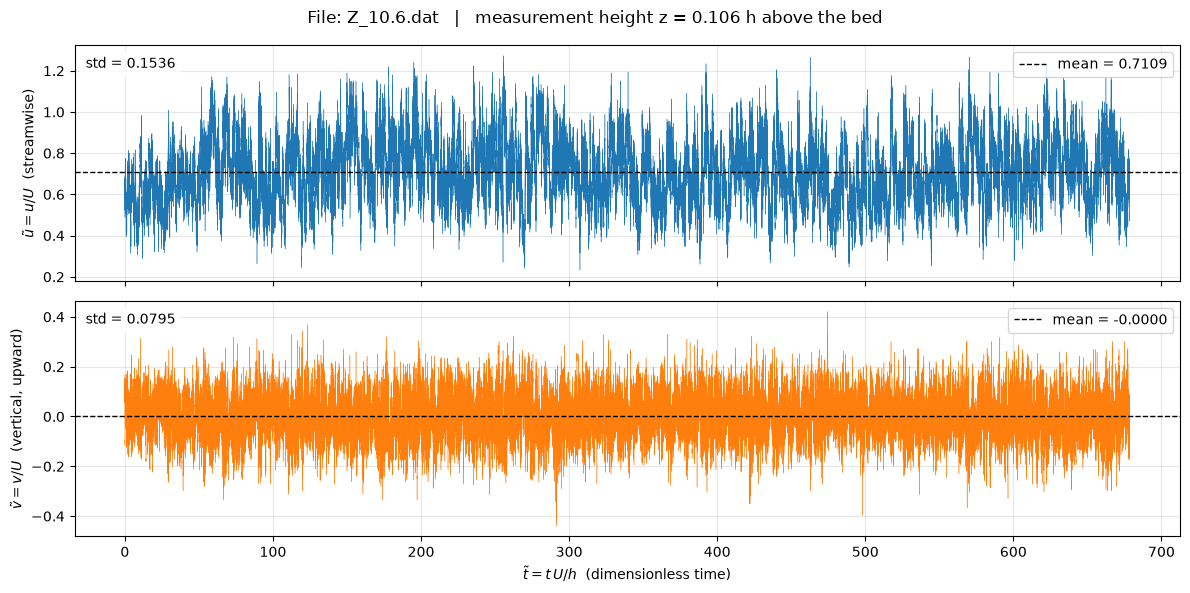

File               : Velocity files for FSI\Z_10.6.dat
Height z/h         : 0.106
Number of samples  : 1134592
Duration t~        : 678.59  (time step dt~ = 0.0006)
u~ : mean = 0.7109, std = 0.1536, min = 0.2333, max = 1.2730
v~ : mean = -0.0000, std = 0.0795, min = -0.4386, max = 0.4211


In [4]:
plot_measurement("Z_10.6.dat")

## 4. `Z_16.8.dat` — measurement at $z = 0.168\,h$

Source: `Velocity files for FSI/Z_16.8.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

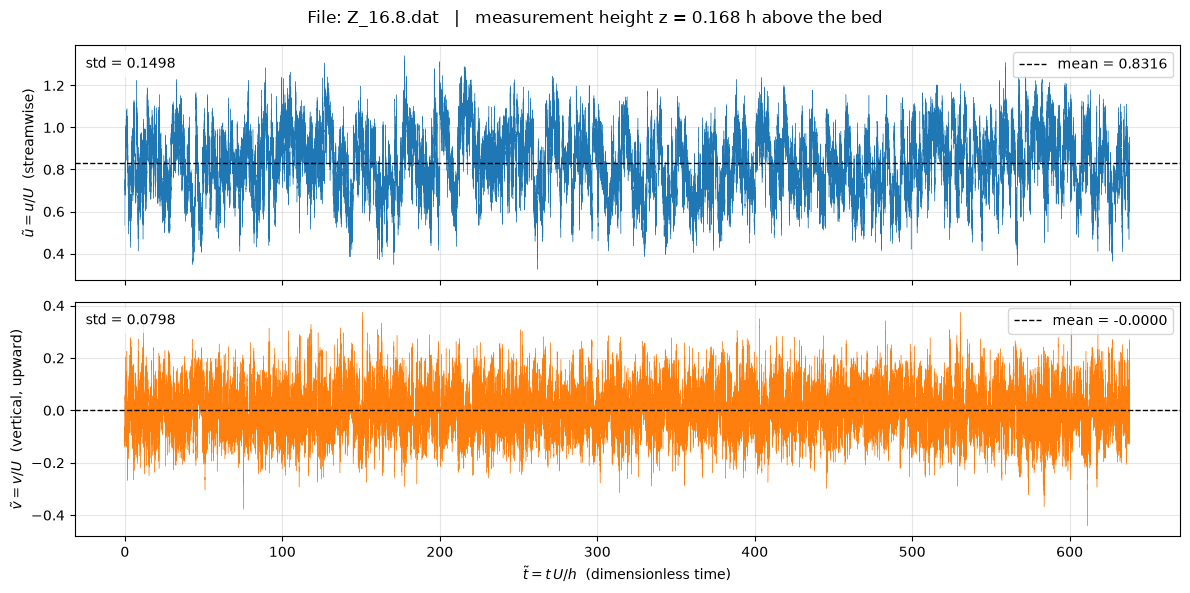

File               : Velocity files for FSI\Z_16.8.dat
Height z/h         : 0.168
Number of samples  : 1067008
Duration t~        : 638.16  (time step dt~ = 0.0006)
u~ : mean = 0.8316, std = 0.1498, min = 0.3249, max = 1.3418
v~ : mean = -0.0000, std = 0.0798, min = -0.4407, max = 0.3745


In [5]:
plot_measurement("Z_16.8.dat")

## 5. `Z_23.3.dat` — measurement at $z = 0.233\,h$

Source: `Velocity files for FSI/Z_23.3.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

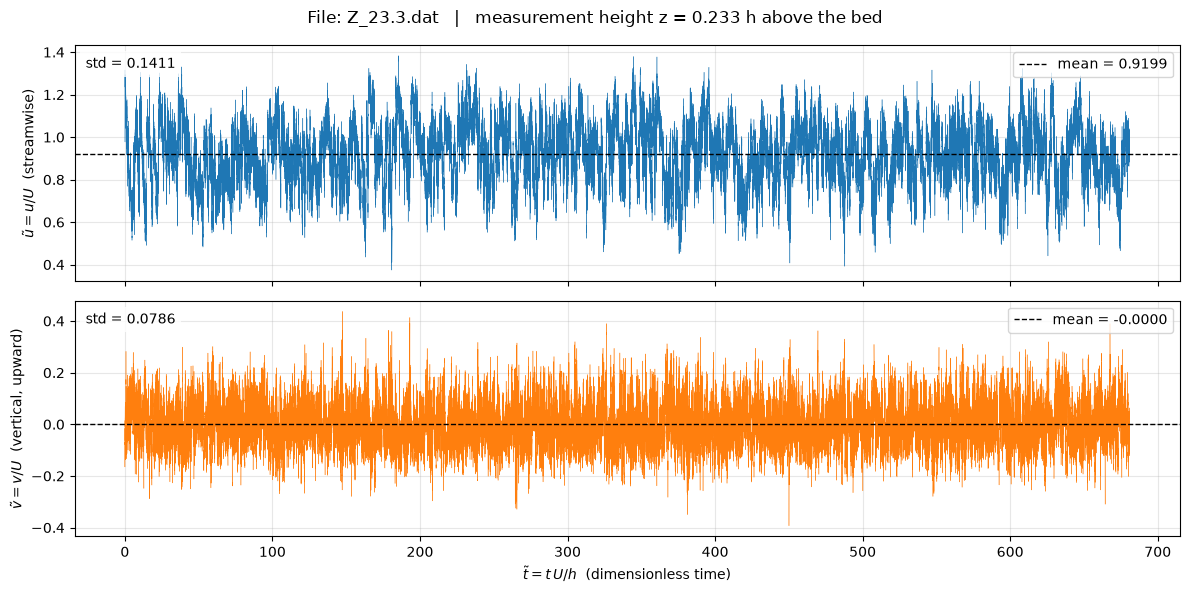

File               : Velocity files for FSI\Z_23.3.dat
Height z/h         : 0.233
Number of samples  : 1138688
Duration t~        : 681.03  (time step dt~ = 0.0006)
u~ : mean = 0.9199, std = 0.1411, min = 0.3741, max = 1.3831
v~ : mean = -0.0000, std = 0.0786, min = -0.3929, max = 0.4372


In [6]:
plot_measurement("Z_23.3.dat")

## 6. `Z_29.7.dat` — measurement at $z = 0.297\,h$

Source: `Velocity files for FSI/Z_29.7.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

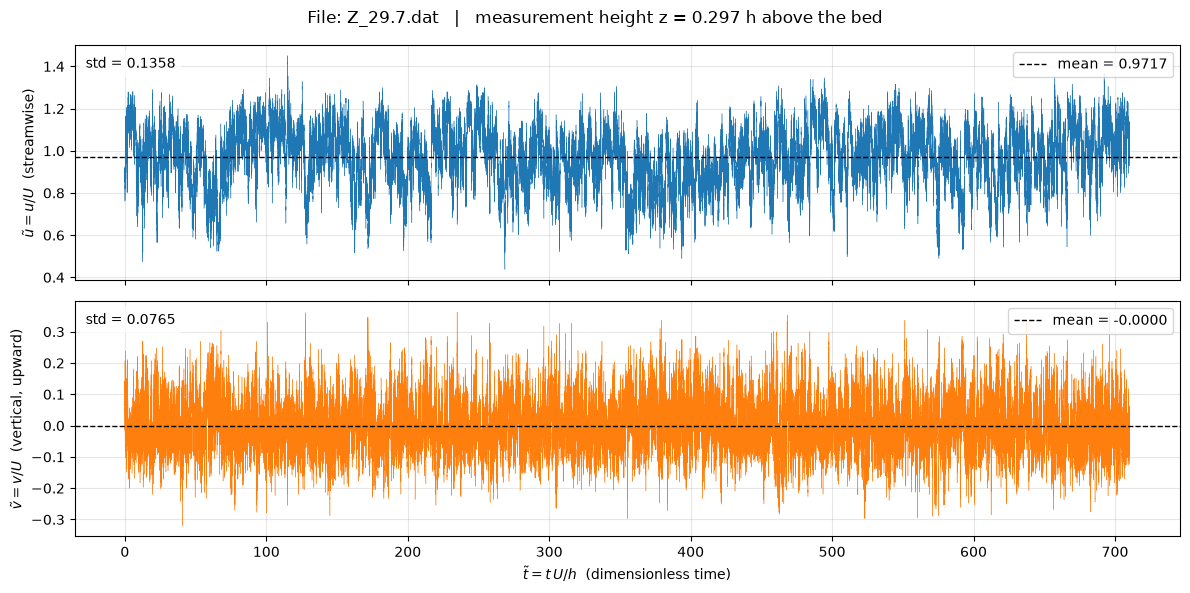

File               : Velocity files for FSI\Z_29.7.dat
Height z/h         : 0.297
Number of samples  : 1187840
Duration t~        : 710.43  (time step dt~ = 0.0006)
u~ : mean = 0.9717, std = 0.1358, min = 0.4372, max = 1.4507
v~ : mean = -0.0000, std = 0.0765, min = -0.3202, max = 0.3631


In [7]:
plot_measurement("Z_29.7.dat")

## 7. `Z_36.0.dat` — measurement at $z = 0.360\,h$

Source: `Velocity files for FSI/Z_36.0.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

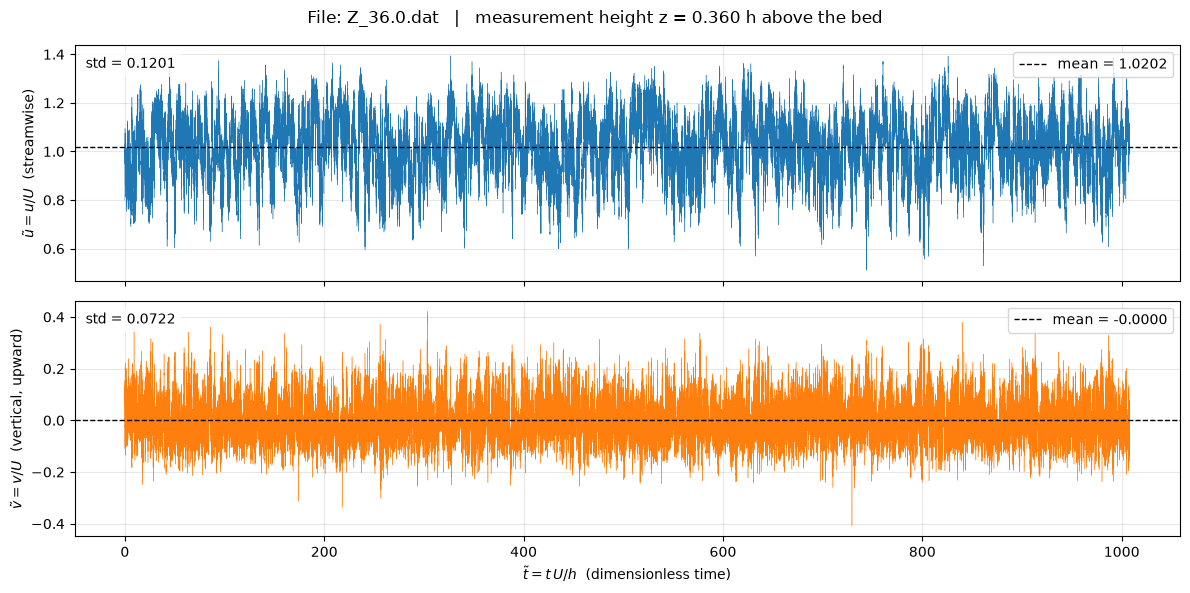

File               : Velocity files for FSI\Z_36.0.dat
Height z/h         : 0.360
Number of samples  : 1685504
Duration t~        : 1008.08  (time step dt~ = 0.0006)
u~ : mean = 1.0202, std = 0.1201, min = 0.5114, max = 1.3941
v~ : mean = -0.0000, std = 0.0722, min = -0.4080, max = 0.4214


In [8]:
plot_measurement("Z_36.0.dat")

## 8. `Z_42.4.dat` — measurement at $z = 0.424\,h$

Source: `Velocity files for FSI/Z_42.4.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

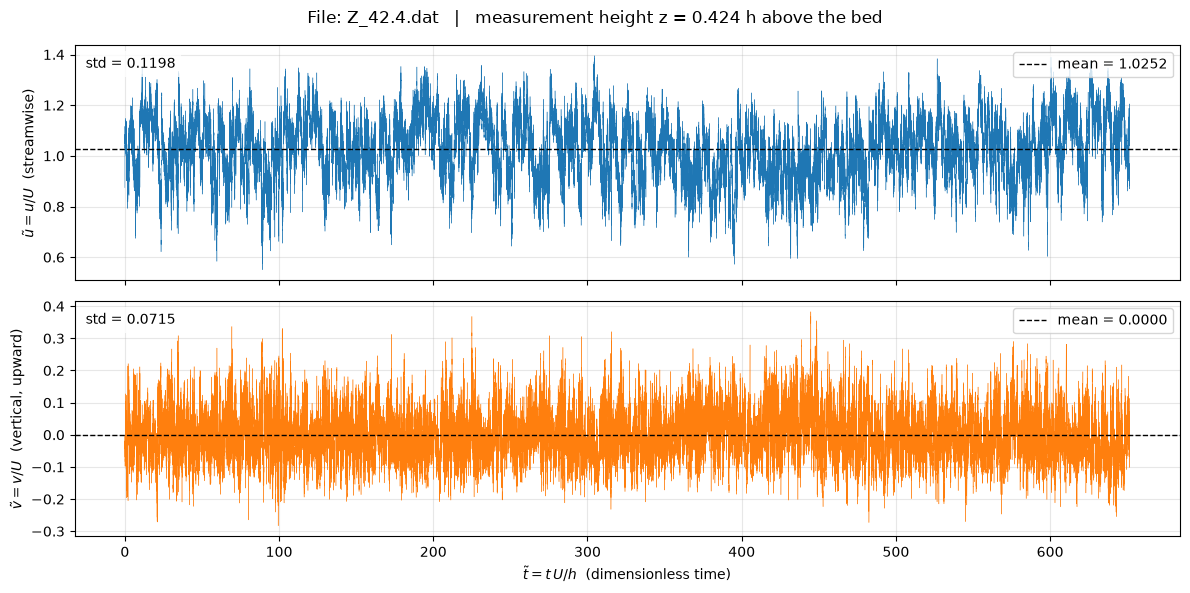

File               : Velocity files for FSI\Z_42.4.dat
Height z/h         : 0.424
Number of samples  : 1089536
Duration t~        : 651.64  (time step dt~ = 0.0006)
u~ : mean = 1.0252, std = 0.1198, min = 0.5503, max = 1.3953
v~ : mean = 0.0000, std = 0.0715, min = -0.2831, max = 0.3828


In [9]:
plot_measurement("Z_42.4.dat")

## 9. `Z_48.8.dat` — measurement at $z = 0.488\,h$

Source: `Velocity files for FSI/Z_48.8.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

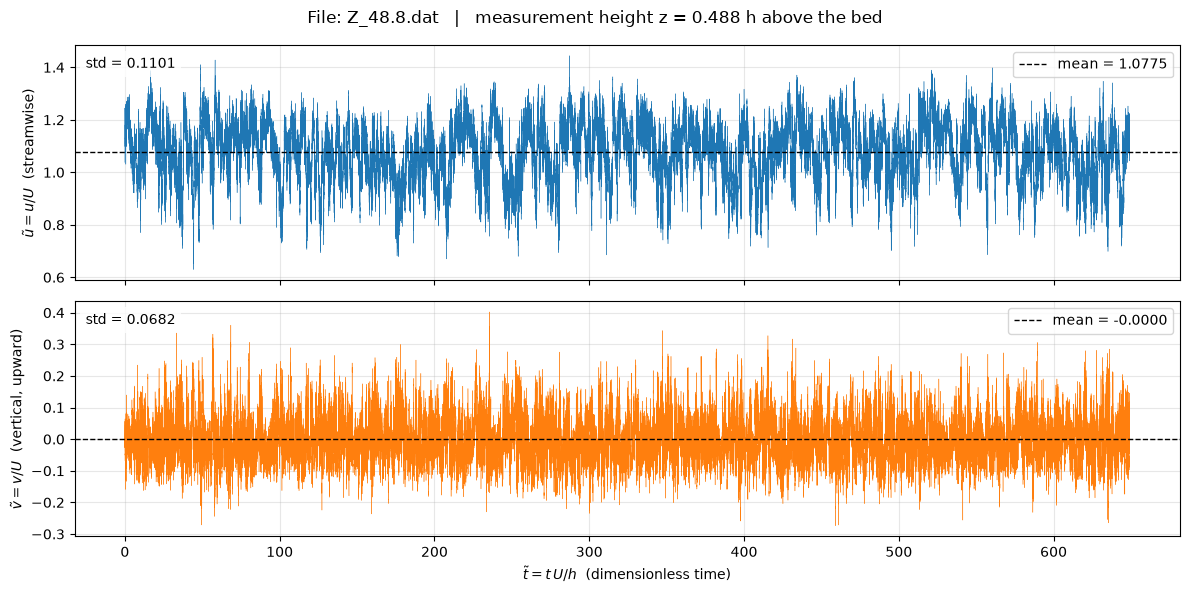

File               : Velocity files for FSI\Z_48.8.dat
Height z/h         : 0.488
Number of samples  : 1085440
Duration t~        : 649.19  (time step dt~ = 0.0006)
u~ : mean = 1.0775, std = 0.1101, min = 0.6295, max = 1.4443
v~ : mean = -0.0000, std = 0.0682, min = -0.2740, max = 0.4023


In [10]:
plot_measurement("Z_48.8.dat")

## 10. `Z_55.3.dat` — measurement at $z = 0.553\,h$

Source: `Velocity files for FSI/Z_55.3.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

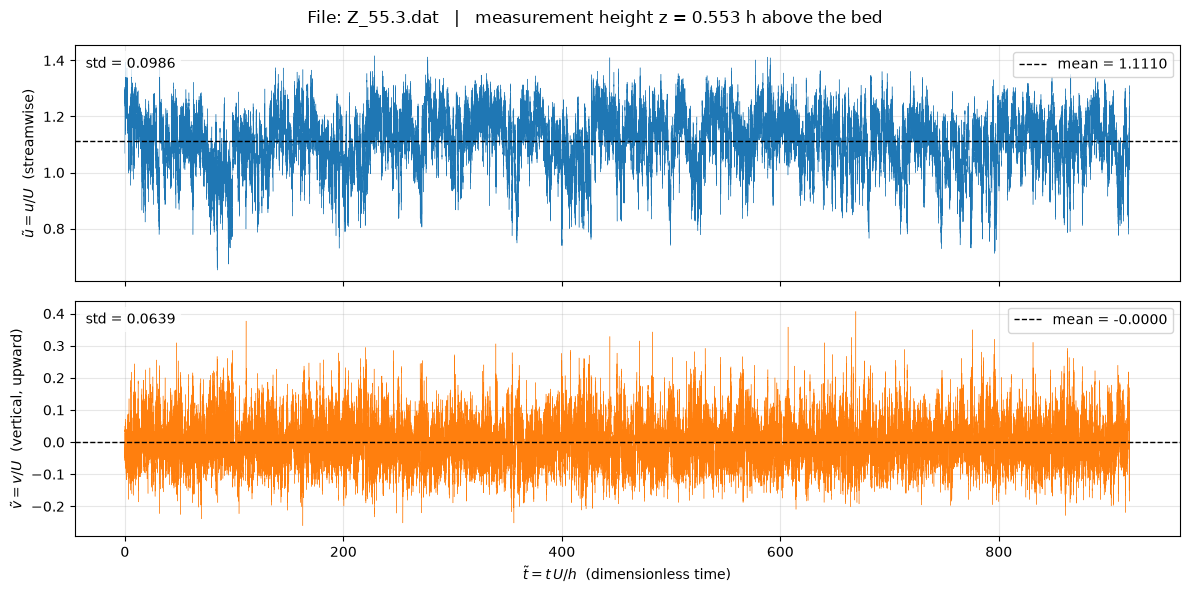

File               : Velocity files for FSI\Z_55.3.dat
Height z/h         : 0.553
Number of samples  : 1538048
Duration t~        : 919.89  (time step dt~ = 0.0006)
u~ : mean = 1.1110, std = 0.0986, min = 0.6517, max = 1.4169
v~ : mean = -0.0000, std = 0.0639, min = -0.2606, max = 0.4068


In [11]:
plot_measurement("Z_55.3.dat")

## 11. `Z_61.5.dat` — measurement at $z = 0.615\,h$

Source: `Velocity files for FSI/Z_61.5.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

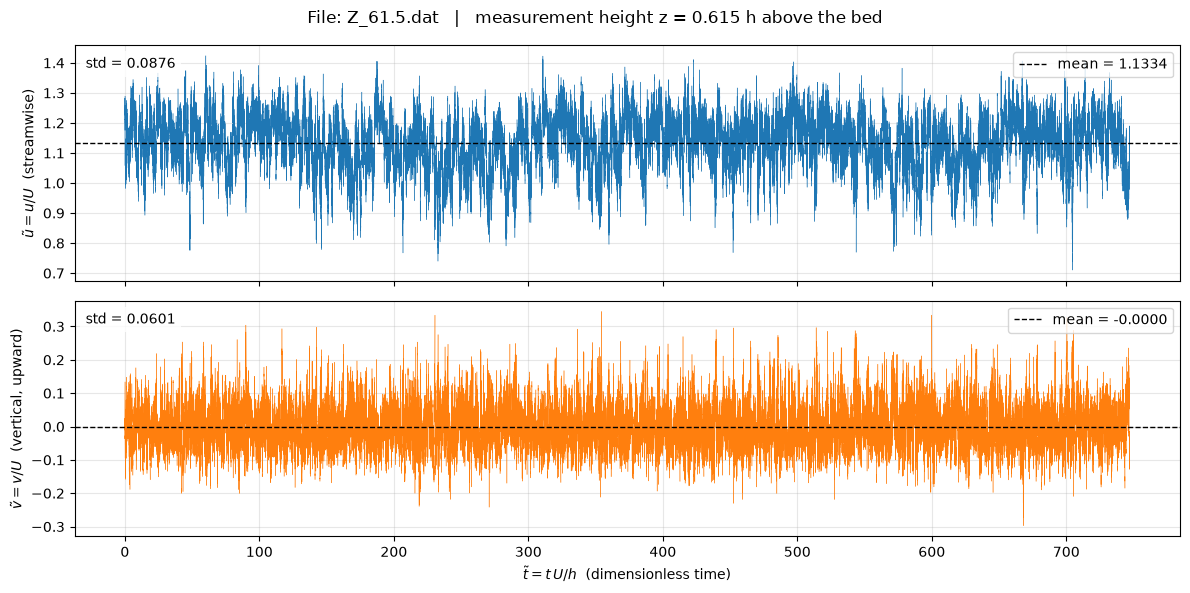

File               : Velocity files for FSI\Z_61.5.dat
Height z/h         : 0.615
Number of samples  : 1249280
Duration t~        : 747.18  (time step dt~ = 0.0006)
u~ : mean = 1.1334, std = 0.0876, min = 0.7102, max = 1.4238
v~ : mean = -0.0000, std = 0.0601, min = -0.2975, max = 0.3451


In [12]:
plot_measurement("Z_61.5.dat")

## 12. `Z_74.4.dat` — measurement at $z = 0.744\,h$

Source: `Velocity files for FSI/Z_74.4.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

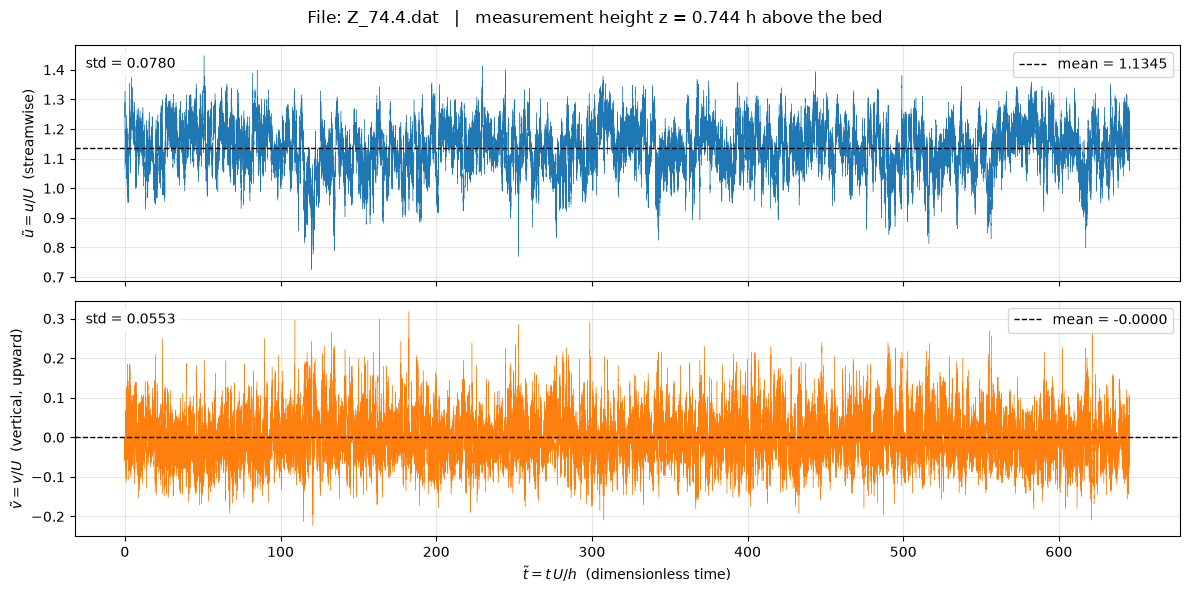

File               : Velocity files for FSI\Z_74.4.dat
Height z/h         : 0.744
Number of samples  : 1079296
Duration t~        : 645.51  (time step dt~ = 0.0006)
u~ : mean = 1.1345, std = 0.0780, min = 0.7236, max = 1.4474
v~ : mean = -0.0000, std = 0.0553, min = -0.2237, max = 0.3181


In [13]:
plot_measurement("Z_74.4.dat")

## 13. `Z_87.0.dat` — measurement at $z = 0.870\,h$

Source: `Velocity files for FSI/Z_87.0.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

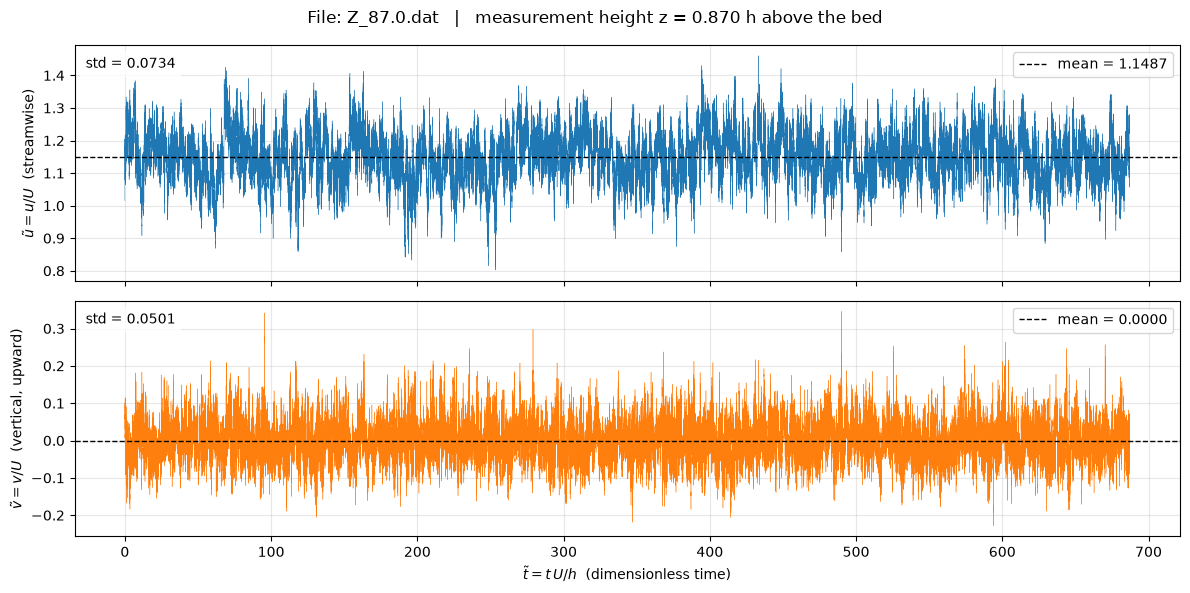

File               : Velocity files for FSI\Z_87.0.dat
Height z/h         : 0.870
Number of samples  : 1148928
Duration t~        : 687.16  (time step dt~ = 0.0006)
u~ : mean = 1.1487, std = 0.0734, min = 0.8021, max = 1.4604
v~ : mean = 0.0000, std = 0.0501, min = -0.2283, max = 0.3458


In [14]:
plot_measurement("Z_87.0.dat")

## 14. `Z_94.4.dat` — measurement at $z = 0.944\,h$

Source: `Velocity files for FSI/Z_94.4.dat`. Top: streamwise velocity $\tilde u$; bottom: vertical velocity $\tilde v$, both as a function of dimensionless time $\tilde t$. The dashed line is the time average.

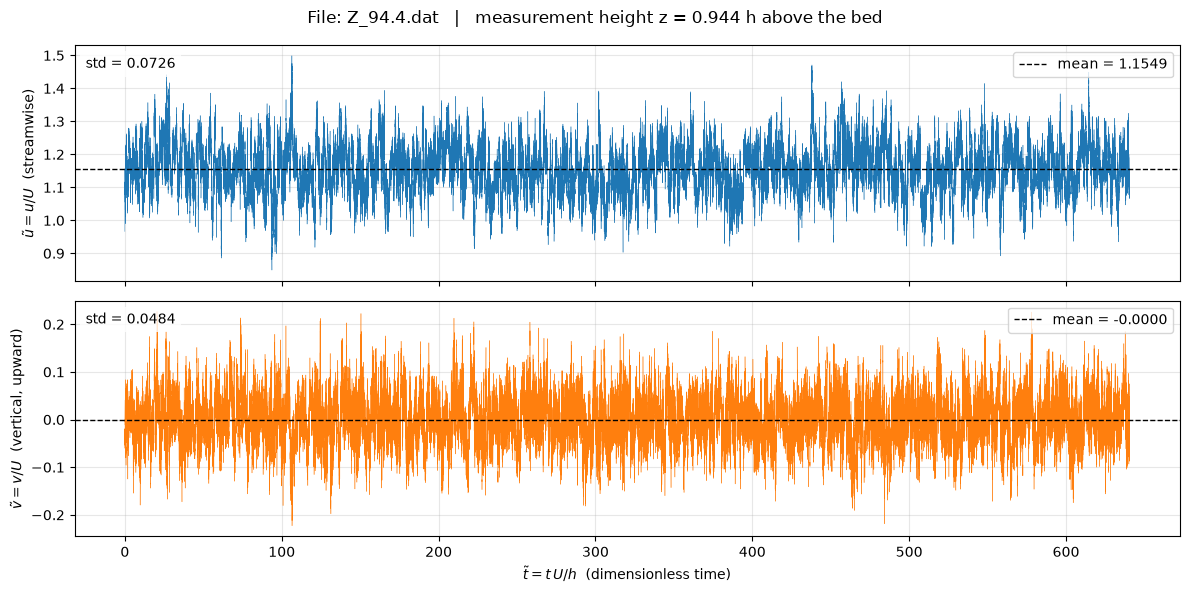

File               : Velocity files for FSI\Z_94.4.dat
Height z/h         : 0.944
Number of samples  : 1071104
Duration t~        : 640.61  (time step dt~ = 0.0006)
u~ : mean = 1.1549, std = 0.0726, min = 0.8493, max = 1.4989
v~ : mean = -0.0000, std = 0.0484, min = -0.2229, max = 0.2270


In [15]:
plot_measurement("Z_94.4.dat")

## Overview of all files

Time average and standard deviation of $\tilde u$ and $\tilde v$ per measurement height (dimensionless).

In [16]:
rows = []
for f in FILES:
    df, zh = load_measurement(f)
    rows.append({"file": f, "z/h": zh, "N samples": len(df), "duration t~": df["t"].iloc[-1],
                 "mean u~": df["u"].mean(), "std u~": df["u"].std(),
                 "mean v~": df["v"].mean(), "std v~": df["v"].std()})
overview = pd.DataFrame(rows).set_index("file")
overview.round(4)

,z/h,N samples,duration t~,mean u~,std u~,mean v~,std v~
file,,,,,,,
Z_02.7.dat,0.027,1081344,646.7381,0.4280,0.1185,0.0,0.0634
Z_07.3.dat,0.073,1142784,683.4846,0.6425,0.1515,-0.0,0.0778
Z_10.6.dat,0.106,1134592,678.5851,0.7109,0.1536,-0.0,0.0795
Z_16.8.dat,0.168,1067008,638.1639,0.8316,0.1498,-0.0,0.0798
Z_23.3.dat,0.233,1138688,681.0348,0.9199,0.1411,-0.0,0.0786
Z_29.7.dat,0.297,1187840,710.4320,0.9717,0.1358,-0.0,0.0765
Z_36.0.dat,0.360,1685504,1008.0788,1.0202,0.1201,-0.0,0.0722
Z_42.4.dat,0.424,1089536,651.6376,1.0252,0.1198,0.0,0.0715
Z_48.8.dat,0.488,1085440,649.1878,1.0775,0.1101,-0.0,0.0682
